# OREX recovered log analysis

Notebook costruito dal txt recuperato dai log Slurm.

Contiene:
- tabella CSV recuperata dai log
- accettanza e lavoro medio vs `nsteps` per diverse repliche
- stima non parametrica di `alpha_best`, escludendo `nsteps=0` dal fit
- costo efficace per swap accettato vs `nsteps`, con `sweep=5`
- costo protocollo pesato col lavoro medio vs `nsteps`, con `sweep=5`
- collapse in

\[
 x = \frac{N_r}{\sqrt{V_{\rm def}}} + \alpha\,\frac{n_{\rm steps} N_r^2}{V_{\rm def}}
\]

con `V_def = 2^3`. `nsteps=0` viene escluso dalla stima di `alpha`, ma incluso nei plot finali come riferimento.


In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

# Se apri il notebook dalla sua cartella usa il path locale;
# se lo apri dalla root del repo usa il fallback sotto plot/.
CSV_PATH = Path('recovered_orex_metrics.csv')
if not CSV_PATH.exists():
    CSV_PATH = Path('plot/orex_recovered_from_txt/recovered_orex_metrics.csv')

OUT_DIR = CSV_PATH.parent
OUT_DIR.mkdir(parents=True, exist_ok=True)

DEFECT_SIDE = 2
V_DEF = float(DEFECT_SIDE ** 3)
SQRT_V_DEF = math.sqrt(V_DEF)

ALPHA_MIN = 0.0
ALPHA_MAX = 1.0
N_ALPHA_GRID = 2001
FIT_EXCLUDE_NSTEPS0 = True

CSV_PATH, OUT_DIR, V_DEF


(PosixPath('recovered_orex_metrics.csv'), PosixPath('.'), 8.0)

In [2]:
df = pd.read_csv(CSV_PATH)

for col in ['world_size', 'nreplicas', 'nsteps', 'swap_acceptance', 'total_accepted',
            'total_proposed', 'work_mean', 'work_sem', 'work_count',
            'thermalization_s', 'measurement_s', 'total_s']:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Errore binomiale grezzo sull'accettanza aggregata.
df['swap_acceptance_sem'] = np.sqrt(
    df['swap_acceptance'] * (1.0 - df['swap_acceptance']) / df['total_proposed']
)

df = df.sort_values(['nreplicas', 'nsteps']).reset_index(drop=True)

NEOREX_CSV_PATH = Path('recovered_neorex_eval_metrics.csv')
if not NEOREX_CSV_PATH.exists():
    NEOREX_CSV_PATH = Path('plot/orex_recovered_from_txt/recovered_neorex_eval_metrics.csv')

if NEOREX_CSV_PATH.exists():
    neodf = pd.read_csv(NEOREX_CSV_PATH)
    for col in [
        'world_size', 'nreplicas', 'nsteps', 'swap_acceptance', 'total_accepted',
        'total_proposed', 'work_mean', 'work_sem', 'work_count',
        'thermalization_s', 'measurement_s', 'total_s', 'flow_applied_updates',
    ]:
        if col in neodf.columns:
            neodf[col] = pd.to_numeric(neodf[col], errors='coerce')
    neodf['swap_acceptance_sem'] = np.sqrt(
        neodf['swap_acceptance'] * (1.0 - neodf['swap_acceptance']) / neodf['total_proposed']
    )
    neodf = neodf.sort_values(['nreplicas', 'nsteps']).reset_index(drop=True)
else:
    neodf = pd.DataFrame(columns=df.columns)

df

,log_file,study_name,run_name,output_dir,world_size,nreplicas,nsteps,collapse_x,swap_acceptance,total_accepted,...,work_mean,work_sem,work_count,thermalization_s,measurement_s,total_s,backend,algorithm,wandb_run_name,swap_acceptance_sem
0,reports/output_neoqcd-orex-array_47246635_0,orex_nsteps_scan_T8L8_d2_bs128_sw5,NaN,/leonardo_scratch/large/userexternal/ecellini/...,4,4,0,1.414214,0.010286,395,...,15.468660,0.035250,38400,0.98,4738.73,4739.72,nccl,orex,NaN,0.000515
1,reports/output_neoqcd-orex-array_47246635_1,orex_nsteps_scan_T8L8_d2_bs128_sw5,NaN,/leonardo_scratch/large/userexternal/ecellini/...,4,4,2,5.414214,0.058750,2256,...,7.980036,0.023260,38400,0.89,7750.59,7751.48,nccl,orex,NaN,0.001200
2,reports/output_neoqcd-orex-array_47246635_2,orex_nsteps_scan_T8L8_d2_bs128_sw5,NaN,/leonardo_scratch/large/userexternal/ecellini/...,4,4,4,9.414214,0.166354,6388,...,4.105233,0.015910,38400,0.98,10495.41,10496.38,nccl,orex,NaN,0.001900
3,reports/output_neoqcd-orex-array_47246635_3,orex_nsteps_scan_T8L8_d2_bs128_sw5,NaN,/leonardo_scratch/large/userexternal/ecellini/...,4,4,6,13.414214,0.259323,9958,...,2.735193,0.012750,38400,1.00,13294.97,13295.97,nccl,orex,NaN,0.002237
4,reports/output_neoqcd-orex-array_47246635_4,orex_nsteps_scan_T8L8_d2_bs128_sw5,NaN,/leonardo_scratch/large/userexternal/ecellini/...,4,4,8,17.414214,0.322604,12388,...,2.069812,0.010870,38400,0.97,16137.20,16138.17,nccl,orex,NaN,0.002386
5,reports/output_neoqcd-orex-array_47246608_0,orex_nsteps_scan_T8L8_d2_bs128_sw5,NaN,/leonardo_scratch/large/userexternal/ecellini/...,8,8,0,2.828427,0.247355,22163,...,2.858547,0.008452,89600,0.96,7855.04,7856.00,nccl,orex,NaN,0.001441
6,reports/output_neoqcd-orex-array_47246608_1,orex_nsteps_scan_T8L8_d2_bs128_sw5,NaN,/leonardo_scratch/large/userexternal/ecellini/...,8,8,2,18.828427,0.423315,37929,...,1.362651,0.005909,89600,1.03,10658.33,10659.36,nccl,orex,NaN,0.001651
7,reports/output_neoqcd-orex-array_47246608_2,orex_nsteps_scan_T8L8_d2_bs128_sw5,NaN,/leonardo_scratch/large/userexternal/ecellini/...,8,8,4,34.828427,0.557723,49972,...,0.715913,0.004192,89600,1.02,13467.69,13468.71,nccl,orex,NaN,0.001659
8,reports/output_neoqcd-orex-array_47246608_3,orex_nsteps_scan_T8L8_d2_bs128_sw5,NaN,/leonardo_scratch/large/userexternal/ecellini/...,8,8,6,50.828427,0.625156,56014,...,0.492444,0.003431,89600,1.03,16324.48,16325.51,nccl,orex,NaN,0.001617
9,reports/output_neoqcd-orex-array_47246608_4,orex_nsteps_scan_T8L8_d2_bs128_sw5,NaN,/leonardo_scratch/large/userexternal/ecellini/...,8,8,8,66.828427,0.667913,59845,...,0.381195,0.002983,89600,0.99,19128.22,19129.20,nccl,orex,NaN,0.001573


In [3]:
ordered_csv = OUT_DIR / 'recovered_orex_metrics_ordered.csv'
df.to_csv(ordered_csv, index=False)
ordered_csv


PosixPath('recovered_orex_metrics_ordered.csv')

In [4]:
def by_replica(frame):
    for nrep, sub in frame.groupby('nreplicas', sort=True):
        sub = sub.sort_values('nsteps')
        yield int(nrep), sub


def savefig(fig, name):
    png = OUT_DIR / f'{name}.png'
    pdf = OUT_DIR / f'{name}.pdf'
    fig.savefig(png, dpi=180, bbox_inches='tight')
    fig.savefig(pdf, bbox_inches='tight')
    return png, pdf


def xeff(nreplicas, nsteps, alpha, v_def=V_DEF):
    nreplicas = np.asarray(nreplicas, dtype=float)
    nsteps = np.asarray(nsteps, dtype=float)
    return nreplicas / math.sqrt(v_def) + alpha * nsteps * nreplicas * nreplicas / v_def


def inv_xeff(nreplicas, nsteps, alpha, v_def=V_DEF):
    return 1.0 / xeff(nreplicas, nsteps, alpha, v_def=v_def)


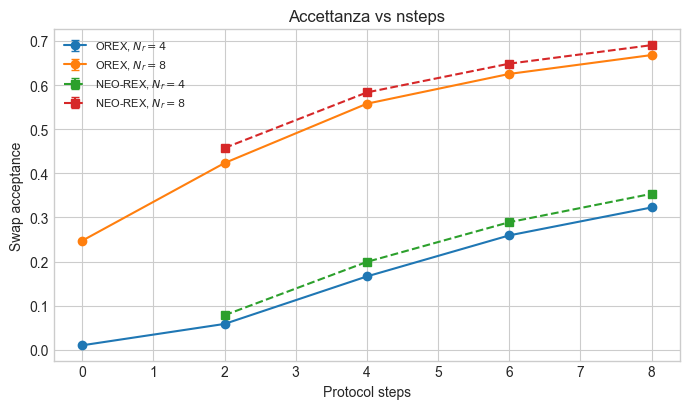

In [5]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for nrep, sub in by_replica(df):
    ax.errorbar(
        sub['nsteps'],
        sub['swap_acceptance'],
        yerr=sub['swap_acceptance_sem'],
        marker='o',
        linestyle='-',
        capsize=3,
        label=f'OREX, $N_r={nrep}$',
    )
for nrep, sub in by_replica(neodf):
    ax.errorbar(
        sub['nsteps'],
        sub['swap_acceptance'],
        yerr=sub['swap_acceptance_sem'],
        marker='s',
        linestyle='--',
        capsize=3,
        label=f'NEO-REX, $N_r={nrep}$',
    )
ax.set_xlabel('Protocol steps')
ax.set_ylabel('Swap acceptance')
ax.set_title('Accettanza vs nsteps')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, 'notebook_acceptance_vs_nsteps')
plt.show()

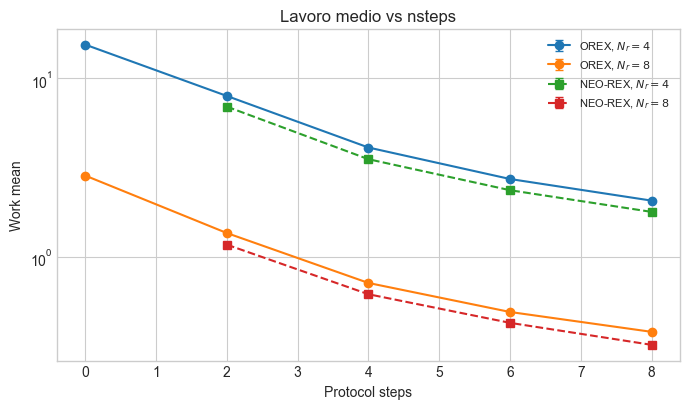

In [6]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for nrep, sub in by_replica(df):
    ax.errorbar(
        sub['nsteps'],
        sub['work_mean'],
        yerr=sub['work_sem'],
        marker='o',
        linestyle='-',
        capsize=3,
        label=f'OREX, $N_r={nrep}$',
    )
for nrep, sub in by_replica(neodf):
    ax.errorbar(
        sub['nsteps'],
        sub['work_mean'],
        yerr=sub['work_sem'],
        marker='s',
        linestyle='--',
        capsize=3,
        label=f'NEO-REX, $N_r={nrep}$',
    )
ax.set_xlabel('Protocol steps')
ax.set_ylabel('Work mean')
ax.set_yscale('log')
ax.set_title('Lavoro medio vs nsteps')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, 'notebook_work_vs_nsteps')
plt.show()

In [7]:
fit_df = df.copy()
if FIT_EXCLUDE_NSTEPS0:
    fit_df = fit_df[fit_df['nsteps'] != 0].copy()

fit_df[['nreplicas', 'nsteps', 'swap_acceptance', 'work_mean']]


,nreplicas,nsteps,swap_acceptance,work_mean
1,4,2,0.058750,7.980036
2,4,4,0.166354,4.105233
3,4,6,0.259323,2.735193
4,4,8,0.322604,2.069812
6,8,2,0.423315,1.362651
7,8,4,0.557723,0.715913
8,8,6,0.625156,0.492444
9,8,8,0.667913,0.381195


In [8]:
def collapse_score_nonparam(y, e, z):
    y = np.asarray(y, dtype=float)
    e = np.asarray(e, dtype=float)
    z = np.asarray(z, dtype=float)

    mask = np.isfinite(y) & np.isfinite(z)
    y, e, z = y[mask], e[mask], z[mask]
    if len(y) < 3:
        return np.inf

    safe_e = np.where(np.isfinite(e) & (e > 0), e, np.ones_like(e))

    dz = z[:, None] - z[None, :]
    dy = y[:, None] - y[None, :]
    var = safe_e[:, None] ** 2 + safe_e[None, :] ** 2

    tri = np.triu(np.ones_like(dz, dtype=bool), k=1)
    dz = np.abs(dz[tri])
    dy = dy[tri]
    var = var[tri]
    if len(dz) == 0:
        return np.inf

    sigma = np.median(dz)
    if not np.isfinite(sigma) or sigma <= 0:
        sigma = max(np.max(dz), 1e-6)

    w = np.exp(-0.5 * (dz / sigma) ** 2)
    den = np.sum(w)
    if den <= 0:
        return np.inf
    return float(np.sum(w * (dy * dy / var)) / den)


def estimate_alpha(frame, metric_key, err_key):
    y = frame[metric_key].to_numpy(dtype=float)
    e = frame[err_key].to_numpy(dtype=float)
    nrep = frame['nreplicas'].to_numpy(dtype=float)
    nsteps = frame['nsteps'].to_numpy(dtype=float)

    alphas = np.linspace(ALPHA_MIN, ALPHA_MAX, N_ALPHA_GRID)
    scores = np.empty_like(alphas)
    for i, alpha in enumerate(alphas):
        # Stesso criterio del notebook precedente: score non parametrico su 1/x_eff.
        z = inv_xeff(nrep, nsteps, alpha)
        scores[i] = collapse_score_nonparam(y, e, z)

    idx = int(np.nanargmin(scores))
    return {
        'alpha': float(alphas[idx]),
        'alphas': alphas,
        'scores': scores,
        'score_min': float(scores[idx]),
    }


def estimate_alpha_global(frame):
    acc = estimate_alpha(frame, 'swap_acceptance', 'swap_acceptance_sem')
    work = estimate_alpha(frame, 'work_mean', 'work_sem')

    s_acc = acc['scores'] / max(acc['score_min'], 1e-12)
    s_work = work['scores'] / max(work['score_min'], 1e-12)
    s_tot = s_acc + s_work

    idx = int(np.nanargmin(s_tot))
    return acc, work, {
        'alpha': float(acc['alphas'][idx]),
        'alphas': acc['alphas'],
        'scores': s_tot,
        'score_min': float(s_tot[idx]),
    }


In [9]:
alpha_acc, alpha_work, alpha_global = estimate_alpha_global(fit_df)
ALPHA_BEST = alpha_global['alpha']

# Cambia questo valore a mano per plottare un alpha scelto da te.
# Usa ALPHA_PLOT = ALPHA_BEST per il valore stimato dal fit.
ALPHA_PLOT = ALPHA_BEST

print(f"alpha_acc    = {alpha_acc['alpha']:.6f}  (score={alpha_acc['score_min']:.4f})")
print(f"alpha_work   = {alpha_work['alpha']:.6f}  (score={alpha_work['score_min']:.4f})")
print(f"alpha_global = {alpha_global['alpha']:.6f}  (joint score={alpha_global['score_min']:.4f})")
print(f"alpha_plot   = {ALPHA_PLOT:.6f}")
print(f"fit excludes nsteps=0: {FIT_EXCLUDE_NSTEPS0}")


alpha_acc    = 0.475000  (score=6926.6583)
alpha_work   = 1.000000  (score=13637.5924)
alpha_global = 0.967000  (joint score=2.0122)
alpha_plot   = 0.967000
fit excludes nsteps=0: True


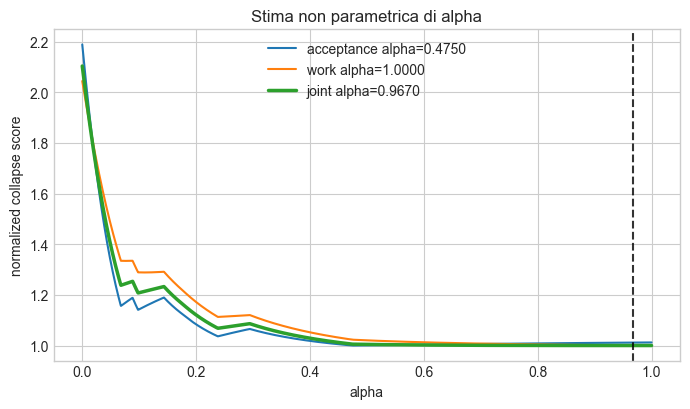

In [10]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
ax.plot(alpha_acc['alphas'], alpha_acc['scores'] / alpha_acc['score_min'], label=f"acceptance alpha={alpha_acc['alpha']:.4f}")
ax.plot(alpha_work['alphas'], alpha_work['scores'] / alpha_work['score_min'], label=f"work alpha={alpha_work['alpha']:.4f}")
ax.plot(alpha_global['alphas'], alpha_global['scores'] / alpha_global['score_min'], lw=2.5, label=f"joint alpha={ALPHA_BEST:.4f}")
ax.axvline(ALPHA_BEST, color='k', ls='--', alpha=0.8)
ax.set_xlabel('alpha')
ax.set_ylabel('normalized collapse score')
ax.set_title('Stima non parametrica di alpha')
ax.legend()
fig.tight_layout()
savefig(fig, 'notebook_alpha_scan')
plt.show()


## Costo efficace per swap accettato

Uso

\[
y = \frac{N_r \cdot sweep + 2(N_r-1)n_{steps}}{acceptance}
\]

con `sweep=5`.

,nreplicas,nsteps,swap_acceptance,effective_cost_per_accept
0,4,0,0.010286,1944.390434
1,4,2,0.058750,544.680851
2,4,4,0.166354,264.496195
3,4,6,0.259323,215.946908
4,4,8,0.322604,210.784739
5,8,0,0.247355,161.710901
6,8,2,0.423315,160.636878
7,8,4,0.557723,172.128458
8,8,6,0.625156,198.350492
9,8,8,0.667913,227.574549


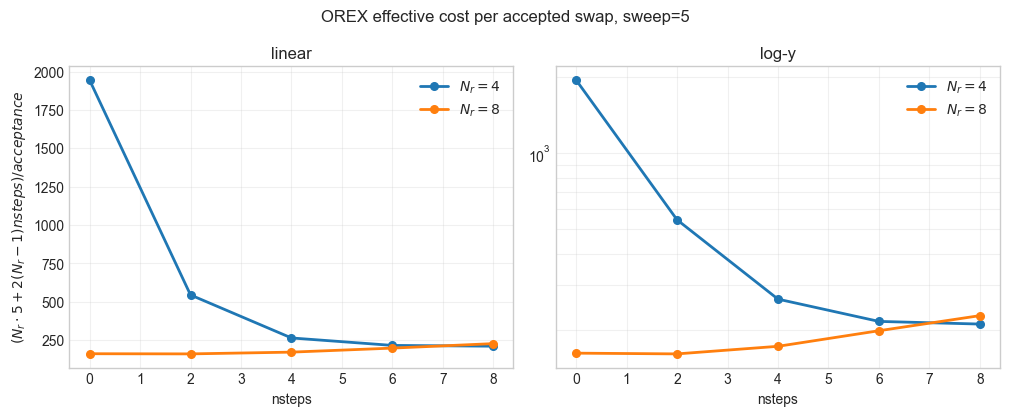

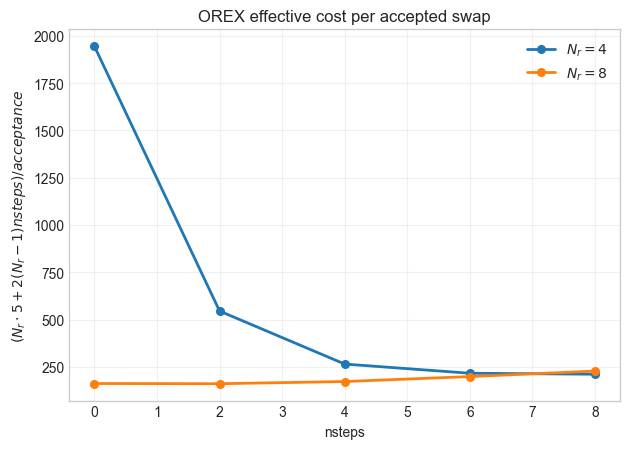

In [11]:
SWEEP = 5.0

cost_df = df.copy()
cost_df['effective_cost_per_accept'] = (
    cost_df['nreplicas'] * SWEEP
    + 2.0 * (cost_df['nreplicas'] - 1.0) * cost_df['nsteps']
) / cost_df['swap_acceptance']

cost_csv = OUT_DIR / 'effective_cost_per_accept_sweep5.csv'
cost_df[['nreplicas', 'nsteps', 'swap_acceptance', 'effective_cost_per_accept']].to_csv(cost_csv, index=False)

fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.2), sharex=True)
for ax, logy in zip(axes, [False, True]):
    for nr, sub in sorted(cost_df.groupby('nreplicas')):
        sub = sub.sort_values('nsteps')
        ax.plot(
            sub['nsteps'],
            sub['effective_cost_per_accept'],
            marker='o',
            linewidth=2.0,
            markersize=5.5,
            label=fr'$N_r={int(nr)}$',
        )
    ax.set_xlabel('nsteps')
    ax.grid(True, alpha=0.28, which='both')
    ax.legend(frameon=False)
    ax.set_title('log-y' if logy else 'linear')
    if logy:
        ax.set_yscale('log')

axes[0].set_ylabel(r'$(N_r \cdot 5 + 2(N_r-1)nsteps) / acceptance$')
fig.suptitle('OREX effective cost per accepted swap, sweep=5')
fig.tight_layout()

for ext in ['png', 'pdf']:
    fig.savefig(OUT_DIR / f'effective_cost_per_accept_sweep5_linear_logy.{ext}', dpi=220 if ext == 'png' else None)

fig, ax = plt.subplots(figsize=(6.4, 4.6))
for nr, sub in sorted(cost_df.groupby('nreplicas')):
    sub = sub.sort_values('nsteps')
    ax.plot(
        sub['nsteps'],
        sub['effective_cost_per_accept'],
        marker='o',
        linewidth=2.0,
        markersize=5.5,
        label=fr'$N_r={int(nr)}$',
    )
ax.set_xlabel('nsteps')
ax.set_ylabel(r'$(N_r \cdot 5 + 2(N_r-1)nsteps) / acceptance$')
ax.set_title('OREX effective cost per accepted swap')
ax.grid(True, alpha=0.28)
ax.legend(frameon=False)
fig.tight_layout()
for ext in ['png', 'pdf']:
    fig.savefig(OUT_DIR / f'effective_cost_per_accept_sweep5.{ext}', dpi=220 if ext == 'png' else None)

cost_df[['nreplicas', 'nsteps', 'swap_acceptance', 'effective_cost_per_accept']].sort_values(['nreplicas', 'nsteps'])

## Costo pesato con il lavoro

Uso

\[
y = \left[N_r \cdot sweep + 2(N_r-1)n_{steps}\right] \langle W \rangle
\]

con `sweep=5`.

,nreplicas,nsteps,protocol_cost,work_mean,work_sem,effective_cost_times_work,effective_cost_times_work_sem
0,4,0,20.0,15.468660,0.035250,309.373200,0.705000
1,4,2,32.0,7.980036,0.023260,255.361152,0.744320
2,4,4,44.0,4.105233,0.015910,180.630252,0.700040
3,4,6,56.0,2.735193,0.012750,153.170808,0.714000
4,4,8,68.0,2.069812,0.010870,140.747216,0.739160
5,8,0,40.0,2.858547,0.008452,114.341880,0.338080
6,8,2,68.0,1.362651,0.005909,92.660268,0.401812
7,8,4,96.0,0.715913,0.004192,68.727629,0.402432
8,8,6,124.0,0.492444,0.003431,61.063093,0.425444
9,8,8,152.0,0.381195,0.002983,57.941625,0.453416


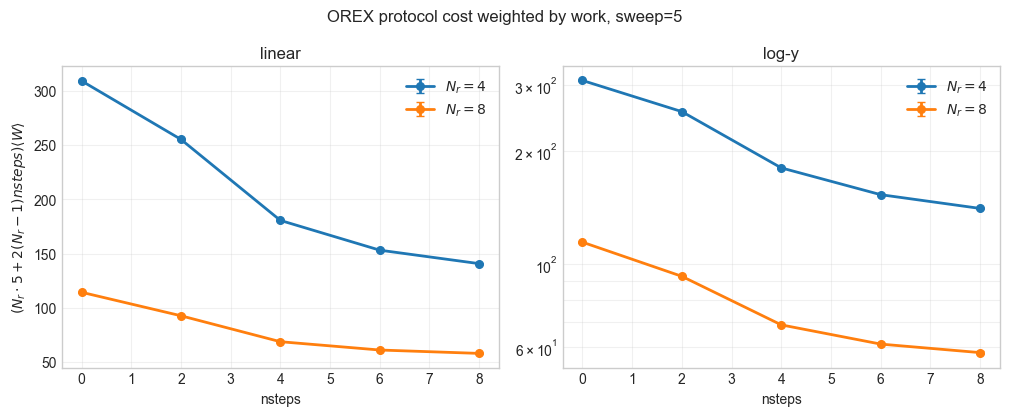

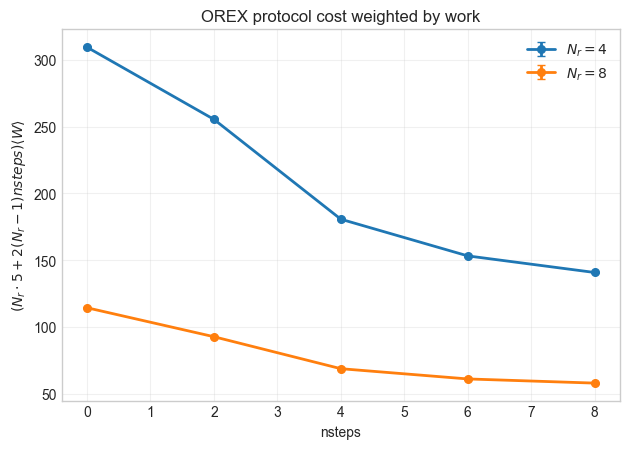

In [12]:
work_cost_df = df.copy()
work_cost_df['protocol_cost'] = (
    work_cost_df['nreplicas'] * SWEEP
    + 2.0 * (work_cost_df['nreplicas'] - 1.0) * work_cost_df['nsteps']
)
work_cost_df['effective_cost_times_work'] = work_cost_df['protocol_cost'] * work_cost_df['work_mean']
work_cost_df['effective_cost_times_work_sem'] = work_cost_df['protocol_cost'] * work_cost_df['work_sem']

work_cost_csv = OUT_DIR / 'effective_cost_times_work_sweep5.csv'
work_cost_df[[
    'nreplicas', 'nsteps', 'protocol_cost', 'work_mean', 'work_sem',
    'effective_cost_times_work', 'effective_cost_times_work_sem'
]].to_csv(work_cost_csv, index=False)

fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.2), sharex=True)
for ax, logy in zip(axes, [False, True]):
    for nr, sub in sorted(work_cost_df.groupby('nreplicas')):
        sub = sub.sort_values('nsteps')
        ax.errorbar(
            sub['nsteps'],
            sub['effective_cost_times_work'],
            yerr=sub['effective_cost_times_work_sem'],
            marker='o',
            linewidth=2.0,
            markersize=5.5,
            capsize=3,
            label=fr'$N_r={int(nr)}$',
        )
    ax.set_xlabel('nsteps')
    ax.grid(True, alpha=0.28, which='both')
    ax.legend(frameon=False)
    ax.set_title('log-y' if logy else 'linear')
    if logy:
        ax.set_yscale('log')

axes[0].set_ylabel(r'$(N_r \cdot 5 + 2(N_r-1)nsteps)\langle W\rangle$')
fig.suptitle('OREX protocol cost weighted by work, sweep=5')
fig.tight_layout()

for ext in ['png', 'pdf']:
    fig.savefig(OUT_DIR / f'effective_cost_times_work_sweep5_linear_logy.{ext}', dpi=220 if ext == 'png' else None)

fig, ax = plt.subplots(figsize=(6.4, 4.6))
for nr, sub in sorted(work_cost_df.groupby('nreplicas')):
    sub = sub.sort_values('nsteps')
    ax.errorbar(
        sub['nsteps'],
        sub['effective_cost_times_work'],
        yerr=sub['effective_cost_times_work_sem'],
        marker='o',
        linewidth=2.0,
        markersize=5.5,
        capsize=3,
        label=fr'$N_r={int(nr)}$',
    )
ax.set_xlabel('nsteps')
ax.set_ylabel(r'$(N_r \cdot 5 + 2(N_r-1)nsteps)\langle W\rangle$')
ax.set_title('OREX protocol cost weighted by work')
ax.grid(True, alpha=0.28)
ax.legend(frameon=False)
fig.tight_layout()
for ext in ['png', 'pdf']:
    fig.savefig(OUT_DIR / f'effective_cost_times_work_sweep5.{ext}', dpi=220 if ext == 'png' else None)

work_cost_df[[
    'nreplicas', 'nsteps', 'protocol_cost', 'work_mean', 'work_sem',
    'effective_cost_times_work', 'effective_cost_times_work_sem'
]].sort_values(['nreplicas', 'nsteps'])

In [13]:
dfc = df.copy()
dfc['collapse_x'] = xeff(dfc['nreplicas'], dfc['nsteps'], ALPHA_PLOT)
dfc[['nreplicas', 'nsteps', 'collapse_x', 'swap_acceptance', 'work_mean']]


,nreplicas,nsteps,collapse_x,swap_acceptance,work_mean
0,4,0,1.414214,0.010286,15.468660
1,4,2,5.282214,0.058750,7.980036
2,4,4,9.150214,0.166354,4.105233
3,4,6,13.018214,0.259323,2.735193
4,4,8,16.886214,0.322604,2.069812
5,8,0,2.828427,0.247355,2.858547
6,8,2,18.300427,0.423315,1.362651
7,8,4,33.772427,0.557723,0.715913
8,8,6,49.244427,0.625156,0.492444
9,8,8,64.716427,0.667913,0.381195


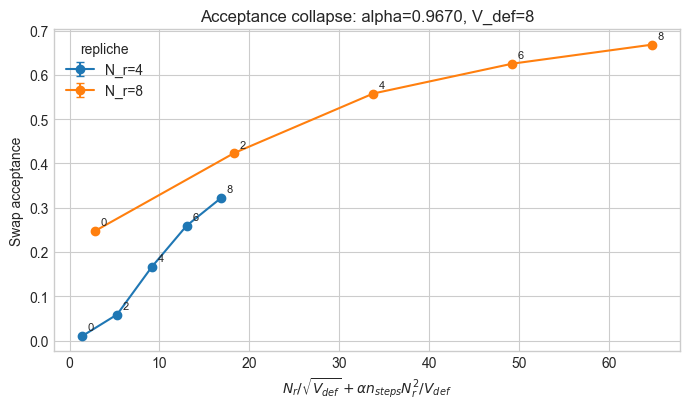

In [14]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for nrep, sub in by_replica(dfc):
    ax.errorbar(
        sub['collapse_x'],
        sub['swap_acceptance'],
        yerr=sub['swap_acceptance_sem'],
        marker='o',
        capsize=3,
        label=f'N_r={nrep}',
    )
    for _, row in sub.iterrows():
        ax.annotate(int(row['nsteps']), (row['collapse_x'], row['swap_acceptance']),
                    textcoords='offset points', xytext=(4, 4), fontsize=8)
ax.set_xlabel(r'$N_r / \sqrt{V_{def}} + \alpha n_{steps} N_r^2 / V_{def}$')
ax.set_ylabel('Swap acceptance')
ax.set_title(f'Acceptance collapse: alpha={ALPHA_PLOT:.4f}, V_def={V_DEF:g}')
ax.legend(title='repliche')
fig.tight_layout()
savefig(fig, f'notebook_collapse_acceptance_alpha{str(round(ALPHA_PLOT, 6)).replace(".", "p")}')
plt.show()


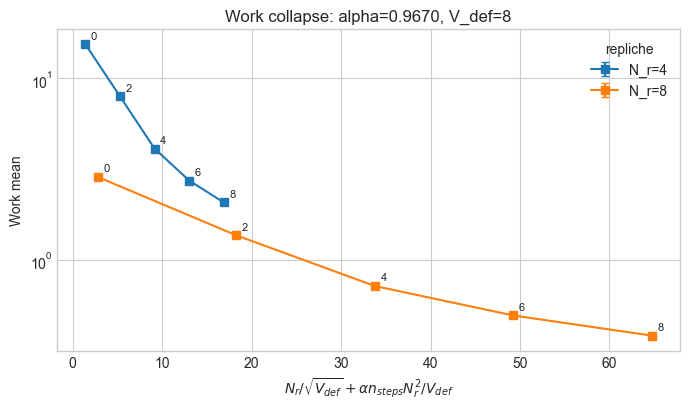

In [15]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for nrep, sub in by_replica(dfc):
    ax.errorbar(
        sub['collapse_x'],
        sub['work_mean'],
        yerr=sub['work_sem'],
        marker='s',
        capsize=3,
        label=f'N_r={nrep}',
    )
    for _, row in sub.iterrows():
        ax.annotate(int(row['nsteps']), (row['collapse_x'], row['work_mean']),
                    textcoords='offset points', xytext=(4, 4), fontsize=8)
ax.set_xlabel(r'$N_r / \sqrt{V_{def}} + \alpha n_{steps} N_r^2 / V_{def}$')
ax.set_ylabel('Work mean')
ax.set_yscale('log')
ax.set_title(f'Work collapse: alpha={ALPHA_PLOT:.4f}, V_def={V_DEF:g}')
ax.legend(title='repliche')
fig.tight_layout()
savefig(fig, f'notebook_collapse_work_alpha{str(round(ALPHA_PLOT, 6)).replace(".", "p")}')
plt.show()


In [16]:
dfc[['nreplicas', 'nsteps', 'collapse_x', 'swap_acceptance', 'swap_acceptance_sem',
     'work_mean', 'work_sem', 'measurement_s', 'total_s', 'log_file']]


,nreplicas,nsteps,collapse_x,swap_acceptance,swap_acceptance_sem,work_mean,work_sem,measurement_s,total_s,log_file
0,4,0,1.414214,0.010286,0.000515,15.468660,0.035250,4738.73,4739.72,reports/output_neoqcd-orex-array_47246635_0
1,4,2,5.282214,0.058750,0.001200,7.980036,0.023260,7750.59,7751.48,reports/output_neoqcd-orex-array_47246635_1
2,4,4,9.150214,0.166354,0.001900,4.105233,0.015910,10495.41,10496.38,reports/output_neoqcd-orex-array_47246635_2
3,4,6,13.018214,0.259323,0.002237,2.735193,0.012750,13294.97,13295.97,reports/output_neoqcd-orex-array_47246635_3
4,4,8,16.886214,0.322604,0.002386,2.069812,0.010870,16137.20,16138.17,reports/output_neoqcd-orex-array_47246635_4
5,8,0,2.828427,0.247355,0.001441,2.858547,0.008452,7855.04,7856.00,reports/output_neoqcd-orex-array_47246608_0
6,8,2,18.300427,0.423315,0.001651,1.362651,0.005909,10658.33,10659.36,reports/output_neoqcd-orex-array_47246608_1
7,8,4,33.772427,0.557723,0.001659,0.715913,0.004192,13467.69,13468.71,reports/output_neoqcd-orex-array_47246608_2
8,8,6,49.244427,0.625156,0.001617,0.492444,0.003431,16324.48,16325.51,reports/output_neoqcd-orex-array_47246608_3
9,8,8,64.716427,0.667913,0.001573,0.381195,0.002983,19128.22,19129.20,reports/output_neoqcd-orex-array_47246608_4


## Collapse a due coefficienti includendo nsteps=0

Ora includo anche `nsteps=0` nel fit e uso

\[
x_{\alpha\beta}
= \alpha\,\frac{N_r}{\sqrt{V_{\rm def}}}
+ \beta\,\frac{n_{\rm steps}N_r^2}{V_{\rm def}}.
\]

Con lo score non parametrico usato sopra, una riscalatura globale di `x` non cambia il fit. Per fissare questa degenerazione uso la normalizzazione

\[
\alpha^2 + \beta^2 = 1,
\]

quindi il parametro fisico stimato e' sostanzialmente il rapporto `beta / alpha`.

In [17]:
def xeff_alpha_beta(nreplicas, nsteps, alpha, beta, v_def=V_DEF):
    nreplicas = np.asarray(nreplicas, dtype=float)
    nsteps = np.asarray(nsteps, dtype=float)
    return (
        alpha * nreplicas / math.sqrt(v_def)
        + beta * nsteps * nreplicas * nreplicas / v_def
    )


def inv_xeff_alpha_beta(nreplicas, nsteps, alpha, beta, v_def=V_DEF):
    x = xeff_alpha_beta(nreplicas, nsteps, alpha, beta, v_def=v_def)
    if np.any(~np.isfinite(x)) or np.any(x <= 0):
        return np.full_like(np.asarray(x, dtype=float), np.nan)
    return 1.0 / x


def estimate_alpha_beta(frame, metric_key, err_key, n_grid=2001):
    y = frame[metric_key].to_numpy(dtype=float)
    e = frame[err_key].to_numpy(dtype=float)
    nrep = frame['nreplicas'].to_numpy(dtype=float)
    nsteps = frame['nsteps'].to_numpy(dtype=float)

    # alpha^2 + beta^2 = 1, alpha > 0 per tenere finito nsteps=0.
    theta = np.linspace(0.0, 0.5 * np.pi - 1e-6, n_grid)
    alphas = np.cos(theta)
    betas = np.sin(theta)
    scores = np.empty_like(theta)

    for i, (alpha, beta) in enumerate(zip(alphas, betas)):
        z = inv_xeff_alpha_beta(nrep, nsteps, alpha, beta)
        scores[i] = collapse_score_nonparam(y, e, z)

    idx = int(np.nanargmin(scores))
    return {
        'alpha': float(alphas[idx]),
        'beta': float(betas[idx]),
        'beta_over_alpha': float(betas[idx] / alphas[idx]),
        'theta': theta,
        'alphas': alphas,
        'betas': betas,
        'scores': scores,
        'score_min': float(scores[idx]),
    }


def estimate_alpha_beta_global(frame, n_grid=2001):
    acc = estimate_alpha_beta(frame, 'swap_acceptance', 'swap_acceptance_sem', n_grid=n_grid)
    work = estimate_alpha_beta(frame, 'work_mean', 'work_sem', n_grid=n_grid)

    s_acc = acc['scores'] / max(acc['score_min'], 1e-12)
    s_work = work['scores'] / max(work['score_min'], 1e-12)
    s_tot = s_acc + s_work

    idx = int(np.nanargmin(s_tot))
    return acc, work, {
        'alpha': float(acc['alphas'][idx]),
        'beta': float(acc['betas'][idx]),
        'beta_over_alpha': float(acc['betas'][idx] / acc['alphas'][idx]),
        'theta': acc['theta'],
        'alphas': acc['alphas'],
        'betas': acc['betas'],
        'scores': s_tot,
        'score_min': float(s_tot[idx]),
    }


fit_ab_df = df.copy()  # Include anche nsteps=0.
alpha_beta_acc, alpha_beta_work, alpha_beta_global = estimate_alpha_beta_global(fit_ab_df)
ALPHA_BETA_BEST = (alpha_beta_global['alpha'], alpha_beta_global['beta'])

# Cambia questi valori a mano per plottare coefficienti scelti da te.
# Usa ALPHA2_PLOT, BETA2_PLOT = ALPHA_BETA_BEST per il valore stimato dal fit.
ALPHA2_PLOT, BETA2_PLOT = ALPHA_BETA_BEST

print(
    f"acceptance: alpha={alpha_beta_acc['alpha']:.6f}, "
    f"beta={alpha_beta_acc['beta']:.6f}, "
    f"beta/alpha={alpha_beta_acc['beta_over_alpha']:.6f}, "
    f"score={alpha_beta_acc['score_min']:.4f}"
)
print(
    f"work:       alpha={alpha_beta_work['alpha']:.6f}, "
    f"beta={alpha_beta_work['beta']:.6f}, "
    f"beta/alpha={alpha_beta_work['beta_over_alpha']:.6f}, "
    f"score={alpha_beta_work['score_min']:.4f}"
)
print(
    f"joint:      alpha={alpha_beta_global['alpha']:.6f}, "
    f"beta={alpha_beta_global['beta']:.6f}, "
    f"beta/alpha={alpha_beta_global['beta_over_alpha']:.6f}, "
    f"score={alpha_beta_global['score_min']:.4f}"
)
print(f"plot:       alpha={ALPHA2_PLOT:.6f}, beta={BETA2_PLOT:.6f}")
print("fit includes nsteps=0: True")

acceptance: alpha=0.987688, beta=0.156434, beta/alpha=0.158384, score=9113.4483
work:       alpha=0.969166, beta=0.246407, beta/alpha=0.254246, score=21339.1468
joint:      alpha=0.987688, beta=0.156434, beta/alpha=0.158384, score=2.0466
plot:       alpha=0.987688, beta=0.156434
fit includes nsteps=0: True


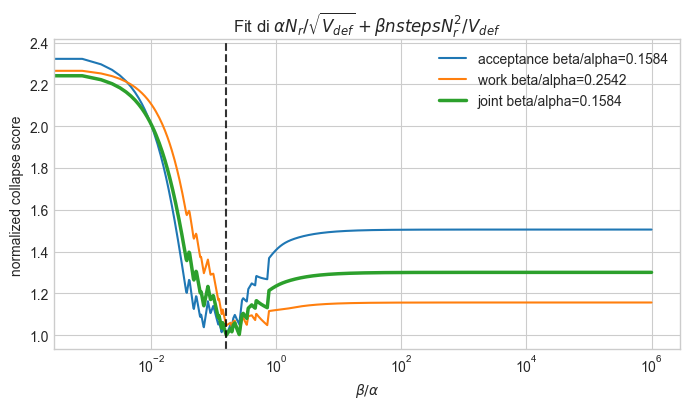

In [18]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
ratio = alpha_beta_acc['betas'] / alpha_beta_acc['alphas']
ax.plot(ratio, alpha_beta_acc['scores'] / alpha_beta_acc['score_min'], label=(
    f"acceptance beta/alpha={alpha_beta_acc['beta_over_alpha']:.4f}"
))
ax.plot(ratio, alpha_beta_work['scores'] / alpha_beta_work['score_min'], label=(
    f"work beta/alpha={alpha_beta_work['beta_over_alpha']:.4f}"
))
ax.plot(ratio, alpha_beta_global['scores'] / alpha_beta_global['score_min'], lw=2.5, label=(
    f"joint beta/alpha={alpha_beta_global['beta_over_alpha']:.4f}"
))
ax.axvline(alpha_beta_global['beta_over_alpha'], color='k', ls='--', alpha=0.8)
ax.set_xlabel(r'$\beta / \alpha$')
ax.set_ylabel('normalized collapse score')
ax.set_title(r'Fit di $\alpha N_r/\sqrt{V_{def}} + \beta nsteps N_r^2/V_{def}$')
ax.set_xscale('log')
ax.legend()
fig.tight_layout()
savefig(fig, 'notebook_alpha_beta_collapse_scan')
plt.show()

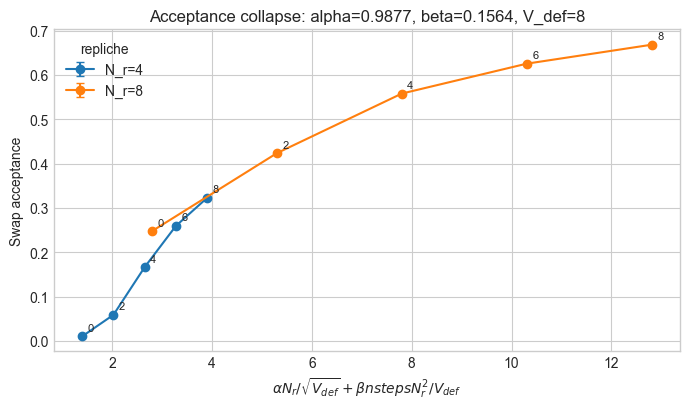

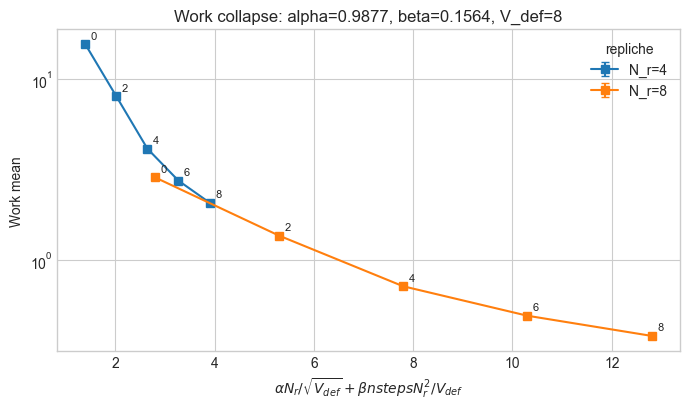

,nreplicas,nsteps,collapse_x_alpha_beta,collapse_inv_x_alpha_beta,swap_acceptance,swap_acceptance_sem,work_mean,work_sem,measurement_s,total_s,log_file
0,4,0,1.396802,0.715921,0.010286,0.000515,15.468660,0.035250,4738.73,4739.72,reports/output_neoqcd-orex-array_47246635_0
1,4,2,2.022540,0.494428,0.058750,0.001200,7.980036,0.023260,7750.59,7751.48,reports/output_neoqcd-orex-array_47246635_1
2,4,4,2.648277,0.377604,0.166354,0.001900,4.105233,0.015910,10495.41,10496.38,reports/output_neoqcd-orex-array_47246635_2
3,4,6,3.274015,0.305435,0.259323,0.002237,2.735193,0.012750,13294.97,13295.97,reports/output_neoqcd-orex-array_47246635_3
4,4,8,3.899752,0.256427,0.322604,0.002386,2.069812,0.010870,16137.20,16138.17,reports/output_neoqcd-orex-array_47246635_4
5,8,0,2.793605,0.357960,0.247355,0.001441,2.858547,0.008452,7855.04,7856.00,reports/output_neoqcd-orex-array_47246608_0
6,8,2,5.296554,0.188802,0.423315,0.001651,1.362651,0.005909,10658.33,10659.36,reports/output_neoqcd-orex-array_47246608_1
7,8,4,7.799504,0.128213,0.557723,0.001659,0.715913,0.004192,13467.69,13468.71,reports/output_neoqcd-orex-array_47246608_2
8,8,6,10.302454,0.097064,0.625156,0.001617,0.492444,0.003431,16324.48,16325.51,reports/output_neoqcd-orex-array_47246608_3
9,8,8,12.805404,0.078092,0.667913,0.001573,0.381195,0.002983,19128.22,19129.20,reports/output_neoqcd-orex-array_47246608_4


In [19]:
df_ab = df.copy()
df_ab['collapse_x_alpha_beta'] = xeff_alpha_beta(
    df_ab['nreplicas'], df_ab['nsteps'], ALPHA2_PLOT, BETA2_PLOT
)
df_ab['collapse_inv_x_alpha_beta'] = 1.0 / df_ab['collapse_x_alpha_beta']

ab_csv = OUT_DIR / 'recovered_orex_metrics_alpha_beta_collapse.csv'
df_ab.to_csv(ab_csv, index=False)

ab_tag = f'a{ALPHA2_PLOT:.4f}_b{BETA2_PLOT:.4f}'.replace('.', 'p')

fig, ax = plt.subplots(figsize=(7.0, 4.2))
for nrep, sub in by_replica(df_ab):
    ax.errorbar(
        sub['collapse_x_alpha_beta'],
        sub['swap_acceptance'],
        yerr=sub['swap_acceptance_sem'],
        marker='o',
        capsize=3,
        label=f'N_r={nrep}',
    )
    for _, row in sub.iterrows():
        ax.annotate(int(row['nsteps']), (row['collapse_x_alpha_beta'], row['swap_acceptance']),
                    textcoords='offset points', xytext=(4, 4), fontsize=8)
ax.set_xlabel(r'$\alpha N_r/\sqrt{V_{def}} + \beta nsteps N_r^2/V_{def}$')
ax.set_ylabel('Swap acceptance')
ax.set_title(
    f'Acceptance collapse: alpha={ALPHA2_PLOT:.4f}, beta={BETA2_PLOT:.4f}, V_def={V_DEF:g}'
)
ax.legend(title='repliche')
fig.tight_layout()
savefig(fig, f'notebook_collapse_acceptance_alpha_beta_{ab_tag}')
plt.show()

fig, ax = plt.subplots(figsize=(7.0, 4.2))
for nrep, sub in by_replica(df_ab):
    ax.errorbar(
        sub['collapse_x_alpha_beta'],
        sub['work_mean'],
        yerr=sub['work_sem'],
        marker='s',
        capsize=3,
        label=f'N_r={nrep}',
    )
    for _, row in sub.iterrows():
        ax.annotate(int(row['nsteps']), (row['collapse_x_alpha_beta'], row['work_mean']),
                    textcoords='offset points', xytext=(4, 4), fontsize=8)
ax.set_xlabel(r'$\alpha N_r/\sqrt{V_{def}} + \beta nsteps N_r^2/V_{def}$')
ax.set_ylabel('Work mean')
ax.set_yscale('log')
ax.set_title(
    f'Work collapse: alpha={ALPHA2_PLOT:.4f}, beta={BETA2_PLOT:.4f}, V_def={V_DEF:g}'
)
ax.legend(title='repliche')
fig.tight_layout()
savefig(fig, f'notebook_collapse_work_alpha_beta_{ab_tag}')
plt.show()

df_ab[[
    'nreplicas', 'nsteps', 'collapse_x_alpha_beta', 'collapse_inv_x_alpha_beta',
    'swap_acceptance', 'swap_acceptance_sem', 'work_mean', 'work_sem',
    'measurement_s', 'total_s', 'log_file'
]].sort_values(['nreplicas', 'nsteps'])

## Simple OREX/NEO-REX scaling

Ansatz minimale, senza offset e senza termini superiori:

\[
x = N_r + \alpha\, n_{steps}(N_r-1)^2,
\qquad
W \simeq \frac{C}{x}.
\]

Il fit sceglie solo `alpha` e una normalizzazione globale `C`. I punti con `nsteps=0` sono esclusi.

In [20]:
simple_orex = df[df['nsteps'] > 0].copy()
simple_neorex = neodf[neodf['nsteps'] > 0].copy()


def simple_x(nreplicas, nsteps, alpha):
    nreplicas = np.asarray(nreplicas, dtype=float)
    nsteps = np.asarray(nsteps, dtype=float)
    return nreplicas + float(alpha) * nsteps * (nreplicas - 1.0) * (nreplicas - 1.0)


def fit_simple_alpha_C(frame, alpha_max=100.0):
    nrep = frame['nreplicas'].to_numpy(dtype=float)
    nsteps = frame['nsteps'].to_numpy(dtype=float)
    work = frame['work_mean'].to_numpy(dtype=float)
    work_sem = frame['work_sem'].to_numpy(dtype=float)

    mask = np.isfinite(nrep) & np.isfinite(nsteps) & np.isfinite(work) & np.isfinite(work_sem)
    mask &= (nsteps > 0) & (work > 0) & (work_sem > 0)
    nrep, nsteps, work, work_sem = nrep[mask], nsteps[mask], work[mask], work_sem[mask]

    def fit_C_for_alpha(alpha):
        x = simple_x(nrep, nsteps, alpha)
        if np.any(~np.isfinite(x)) or np.any(x <= 0):
            return np.nan, np.inf
        basis = 1.0 / x
        weights = 1.0 / (work_sem * work_sem)
        C = float(np.sum(weights * basis * work) / np.sum(weights * basis * basis))
        pred = C * basis
        residual = work - pred
        chi2 = float(np.sum(weights * residual * residual))
        dof = max(1, len(work) - 2)
        return C, chi2 / dof

    def score(alpha):
        _, chi2_dof = fit_C_for_alpha(alpha)
        return chi2_dof

    try:
        from scipy.optimize import minimize_scalar
        opt = minimize_scalar(score, bounds=(0.0, float(alpha_max)), method='bounded', options={'xatol': 1e-12})
        alpha = float(opt.x)
    except Exception:
        grid = np.linspace(0.0, float(alpha_max), 20001)
        vals = np.asarray([score(a) for a in grid])
        alpha = float(grid[int(np.nanargmin(vals))])

    C, chi2_dof = fit_C_for_alpha(alpha)
    x = simple_x(nrep, nsteps, alpha)
    pred = C / x
    residual = work - pred
    return {
        'alpha': float(alpha),
        'C': float(C),
        'chi2_dof': float(chi2_dof),
        'mean_relative_residual': float(np.mean(residual / work)),
        'max_abs_relative_residual': float(np.max(np.abs(residual / work))),
        'rel_spread_Wx': float(np.std(work * x, ddof=1) / np.mean(work * x)) if len(work) > 1 else float('nan'),
        'n_points': int(len(work)),
    }

simple_fits = {
    'OREX': fit_simple_alpha_C(simple_orex),
    'NEO-REX pretrained': fit_simple_alpha_C(simple_neorex),
}

for label, fit in simple_fits.items():
    print(
        f"{label}: alpha={fit['alpha']:.8f}, C={fit['C']:.8e}, "
        f"chi2/dof={fit['chi2_dof']:.3f}, rel_spread_Wx={fit['rel_spread_Wx']:.4f}, "
        f"mean_rel_residual={fit['mean_relative_residual']:.3e}, "
        f"max_abs_rel_residual={fit['max_abs_relative_residual']:.3e}, "
        f"n_points={fit['n_points']}"
    )

simple_fits

OREX: alpha=99.99999719, C=1.43826280e+04, chi2/dof=80.165, rel_spread_Wx=0.0373, mean_rel_residual=4.376e-03, max_abs_rel_residual=7.615e-02, n_points=8
NEO-REX pretrained: alpha=99.99999846, C=1.24465615e+04, chi2/dof=70.228, rel_spread_Wx=0.0363, mean_rel_residual=1.368e-03, max_abs_rel_residual=8.187e-02, n_points=8


{'OREX': {'alpha': 99.99999719258996,
  'C': 14382.628030938951,
  'chi2_dof': 80.16488389121409,
  'mean_relative_residual': 0.004375540462262369,
  'max_abs_relative_residual': 0.07615087824423952,
  'rel_spread_Wx': 0.03729500795200694,
  'n_points': 8},
 'NEO-REX pretrained': {'alpha': 99.99999846277767,
  'C': 12446.561502436218,
  'chi2_dof': 70.22799938240748,
  'mean_relative_residual': 0.0013680039713237831,
  'max_abs_relative_residual': 0.08186703733218272,
  'rel_spread_Wx': 0.036334023933640394,
  'n_points': 8}}

In [21]:
def make_simple_scaling_frame(frame, algorithm, fit):
    out = frame.copy()
    out['algorithm'] = algorithm
    out['simple_alpha'] = float(fit['alpha'])
    out['simple_C'] = float(fit['C'])
    out['simple_x'] = simple_x(out['nreplicas'], out['nsteps'], fit['alpha'])
    out['simple_inv_x'] = 1.0 / out['simple_x']
    out['simple_prediction'] = fit['C'] * out['simple_inv_x']
    out['simple_residual'] = out['work_mean'] - out['simple_prediction']
    out['simple_relative_residual'] = out['simple_residual'] / out['work_mean']
    out['work_times_simple_x'] = out['work_mean'] * out['simple_x']
    out['work_times_simple_x_sem'] = out['work_sem'] * out['simple_x']
    return out

simple_scaling = pd.concat(
    [
        make_simple_scaling_frame(simple_orex, 'OREX', simple_fits['OREX']),
        make_simple_scaling_frame(simple_neorex, 'NEO-REX pretrained', simple_fits['NEO-REX pretrained']),
    ],
    ignore_index=True,
    sort=False,
)

simple_csv = OUT_DIR / 'orex_neorex_simple_Nr_nsteps_scaling.csv'
simple_scaling.to_csv(simple_csv, index=False)
simple_csv

PosixPath('orex_neorex_simple_Nr_nsteps_scaling.csv')

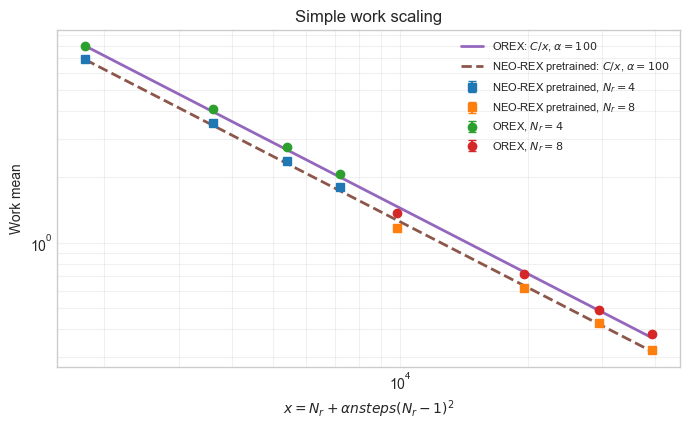

In [22]:
simple_styles = {
    'OREX': {'marker': 'o', 'linestyle': '-'},
    'NEO-REX pretrained': {'marker': 's', 'linestyle': '--'},
}

fig, ax = plt.subplots(figsize=(7.0, 4.4))
for (algorithm, nrep), sub in simple_scaling.groupby(['algorithm', 'nreplicas'], sort=True):
    style = simple_styles.get(algorithm, {'marker': 'o', 'linestyle': '-'})
    sub = sub.sort_values('simple_x')
    ax.errorbar(
        sub['simple_x'],
        sub['work_mean'],
        yerr=sub['work_sem'],
        marker=style['marker'],
        linestyle='none',
        capsize=3,
        label=f'{algorithm}, $N_r={int(nrep)}$',
    )

xmin = float(simple_scaling['simple_x'].min())
xmax = float(simple_scaling['simple_x'].max())
xs = np.geomspace(xmin, xmax, 300)
for algorithm, fit in simple_fits.items():
    ax.plot(
        xs,
        fit['C'] / xs,
        linestyle=simple_styles.get(algorithm, {}).get('linestyle', '-'),
        linewidth=2.0,
        label=f'{algorithm}: $C/x$, $\\alpha={fit["alpha"]:.3g}$',
    )

ax.set_xlabel(r'$x=N_r+\alpha nsteps (N_r-1)^2$')
ax.set_ylabel('Work mean')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title('Simple work scaling')
ax.grid(True, alpha=0.28, which='both')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, 'notebook_simple_work_scaling_Nr_nsteps')
plt.show()

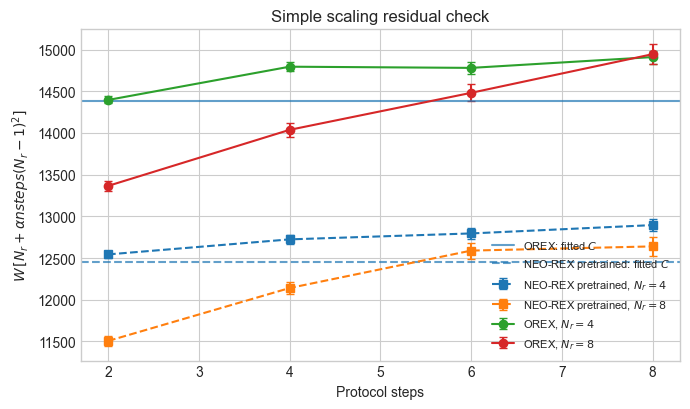

In [23]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for (algorithm, nrep), sub in simple_scaling.groupby(['algorithm', 'nreplicas'], sort=True):
    style = simple_styles.get(algorithm, {'marker': 'o', 'linestyle': '-'})
    sub = sub.sort_values('nsteps')
    ax.errorbar(
        sub['nsteps'],
        sub['work_times_simple_x'],
        yerr=sub['work_times_simple_x_sem'],
        marker=style['marker'],
        linestyle=style['linestyle'],
        capsize=3,
        label=f'{algorithm}, $N_r={int(nrep)}$',
    )
for algorithm, fit in simple_fits.items():
    ax.axhline(
        fit['C'],
        linestyle=simple_styles.get(algorithm, {}).get('linestyle', '-'),
        alpha=0.7,
        label=f'{algorithm}: fitted $C$',
    )
ax.set_xlabel('Protocol steps')
ax.set_ylabel(r'$W\,[N_r+\alpha nsteps (N_r-1)^2]$')
ax.set_title('Simple scaling residual check')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, 'notebook_simple_work_times_x_check_Nr_nsteps')
plt.show()

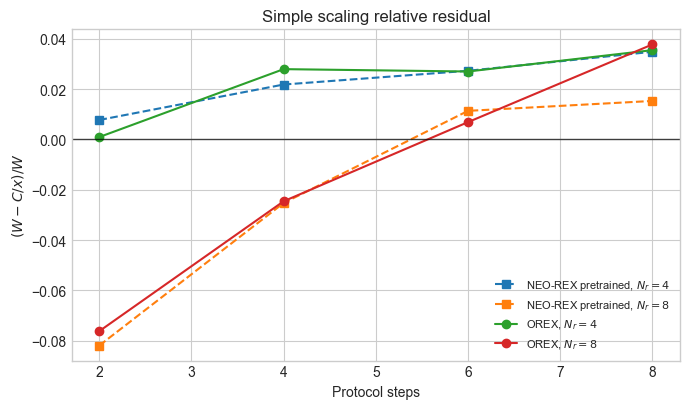

,algorithm,nreplicas,nsteps,simple_alpha,simple_C,simple_x,simple_inv_x,simple_prediction,work_mean,work_sem,simple_residual,simple_relative_residual,work_times_simple_x,swap_acceptance,swap_acceptance_sem,log_file
8,NEO-REX pretrained,4,2,99.999998,12446.561502,1803.999972,0.000554,6.899424,6.952978,0.021290,0.053554,0.007702,12543.172120,0.078464,0.001372,reports/output_neoqcd-neorex-eval-r4_48196475_0
9,NEO-REX pretrained,4,4,99.999998,12446.561502,3603.999945,0.000277,3.453541,3.530432,0.014540,0.076891,0.021779,12723.676733,0.199271,0.002038,reports/output_neoqcd-neorex-eval-r4_48196475_1
10,NEO-REX pretrained,4,6,99.999998,12446.561502,5403.999917,0.000185,2.303213,2.367685,0.011760,0.064472,0.027230,12794.969543,0.289141,0.002314,reports/output_neoqcd-neorex-eval-r4_48196475_2
11,NEO-REX pretrained,4,8,99.999998,12446.561502,7203.999889,0.000139,1.727729,1.789984,0.010170,0.062255,0.034779,12895.044538,0.353490,0.002440,reports/output_neoqcd-neorex-eval-r4_48196475_3
12,NEO-REX pretrained,8,2,99.999998,12446.561502,9807.999849,0.000102,1.269021,1.172992,0.005558,-0.096029,-0.081867,11504.705359,0.457455,0.001664,reports/output_neoqcd-neorex-eval-r8_48196556_0
13,NEO-REX pretrained,8,4,99.999998,12446.561502,19607.999699,0.000051,0.634770,0.619129,0.003950,-0.015640,-0.025262,12139.887128,0.583281,0.001647,reports/output_neoqcd-neorex-eval-r8_48196556_1
14,NEO-REX pretrained,8,6,99.999998,12446.561502,29407.999548,0.000034,0.423237,0.428084,0.003240,0.004847,0.011322,12589.099960,0.648393,0.001595,reports/output_neoqcd-neorex-eval-r8_48196556_2
15,NEO-REX pretrained,8,8,99.999998,12446.561502,39207.999397,0.000026,0.317450,0.322369,0.002788,0.004919,0.015259,12639.427875,0.690379,0.001545,reports/output_neoqcd-neorex-eval-r8_48196556_3
0,OREX,4,2,99.999997,14382.628031,1803.999949,0.000554,7.972632,7.980036,0.023260,0.007404,0.000928,14395.984541,0.058750,0.001200,reports/output_neoqcd-orex-array_47246635_1
1,OREX,4,4,99.999997,14382.628031,3603.999899,0.000277,3.990740,4.105233,0.015910,0.114493,0.027889,14795.259317,0.166354,0.001900,reports/output_neoqcd-orex-array_47246635_2


In [24]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for (algorithm, nrep), sub in simple_scaling.groupby(['algorithm', 'nreplicas'], sort=True):
    style = simple_styles.get(algorithm, {'marker': 'o', 'linestyle': '-'})
    sub = sub.sort_values('nsteps')
    ax.plot(
        sub['nsteps'],
        sub['simple_relative_residual'],
        marker=style['marker'],
        linestyle=style['linestyle'],
        label=f'{algorithm}, $N_r={int(nrep)}$',
    )
ax.axhline(0.0, color='k', linewidth=1.0, alpha=0.7)
ax.set_xlabel('Protocol steps')
ax.set_ylabel(r'$(W-C/x)/W$')
ax.set_title('Simple scaling relative residual')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, 'notebook_simple_work_relative_residual_Nr_nsteps')
plt.show()

simple_scaling[[
    'algorithm', 'nreplicas', 'nsteps', 'simple_alpha', 'simple_C', 'simple_x', 'simple_inv_x',
    'simple_prediction', 'work_mean', 'work_sem', 'simple_residual', 'simple_relative_residual',
    'work_times_simple_x', 'swap_acceptance', 'swap_acceptance_sem', 'log_file'
]].sort_values(['algorithm', 'nreplicas', 'nsteps'])